# Лабораторная работа №3: оптимизация гиперпараметров

Беру задачу из второй лабораторной: [Titanic Dataset](https://www.kaggle.com/datasets/yasserh/titanic-dataset), предсказать, выжил ли пассажир (`Survived`). Метрика та же — F1 для класса `Survived = 1`. Модель — **Gradient Boosting** (`GradientBoostingClassifier`).

Все решения о гиперпараметрах принимаю только по кросс-валидации на train, тест используется один раз — в конце, для финальной проверки уже выбранных моделей.

In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
import time
import warnings
warnings.simplefilter("ignore")
%matplotlib inline

sns.set_theme(style="darkgrid")

RANDOM_STATE = 42

# Часть 1. Задача, данные и модель

Почему эта задача и эта модель:
- Titanic маленький (891 пассажир), поэтому полный перебор по сетке и случайный поиск считаются за минуты, и можно честно проверить много комбинаций.
- Gradient Boosting во второй лабораторной был лучшим по кросс-валидации, и у него есть несколько гиперпараметров, которые напрямую управляют сложностью модели, — на нём хорошо видно недообучение и переобучение.

Данные и подготовка — как во второй лабораторной (подробный анализ данных там):
- то же разбиение 80/20 со стратификацией по `Survived` и `random_state=42`;
- признаки `Pclass`, `Sex`, `Age`, `SibSp`, `Parch`, `Fare`, `Embarked` и `Title` (обращение из имени); `PassengerId`, `Name`, `Ticket` и `Cabin` не используются (идентификаторы и подозрительная `Cabin`);
- пропуски: медиана для числовых признаков и самое частое значение для категорий, категории кодируются one-hot. Всё это внутри `Pipeline`, т.е. считается только по train;
- масштабирование не нужно — модель на деревьях.

`Title` здесь добавляю до разбиения: это построчное преобразование, оно ничего не «учит» по данным, поэтому результат такой же, как если сделать это после разбиения.

In [2]:
data = pd.read_csv("Titanic-Dataset.csv")

print(data.shape)
data.head()

(891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [3]:
from sklearn.model_selection import train_test_split

def add_title(df):
    df = df.copy()
    title = df["Name"].str.extract(r",\s*([^\.]+)\.")[0]
    title = title.replace({"Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs"})
    df["Title"] = title.where(title.isin(["Mr", "Mrs", "Miss", "Master"]), "Rare")
    return df

y = data["Survived"]
X = add_title(data.drop(columns=["Survived"]))

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)

print("Train:", X_train.shape, " Test:", X_test.shape)
pd.DataFrame({
    "train, шт": y_train.value_counts(),
    "test, шт": y_test.value_counts(),
    "train, доля": y_train.value_counts(normalize=True),
    "test, доля": y_test.value_counts(normalize=True),
}).round(3)

Train: (712, 12)  Test: (179, 12)


,"train, шт","test, шт","train, доля","test, доля"
Survived,,,,
0,439,110,0.617,0.615
1,273,69,0.383,0.385


In [4]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

numeric = ["Age", "Fare", "SibSp", "Parch"]
categorical = ["Pclass", "Sex", "Embarked", "Title"]

def make_preprocess():
    return ColumnTransformer([
        ("num", SimpleImputer(strategy="median"), numeric),
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("ohe", OneHotEncoder(handle_unknown="ignore"))
        ]), categorical)
    ])

prep = make_preprocess()
X_ready = prep.fit_transform(X_train)
print(X_train[numeric + categorical].shape, "->", X_ready.shape)
print(list(prep.get_feature_names_out()))

(712, 8) -> (712, 17)
['num__Age', 'num__Fare', 'num__SibSp', 'num__Parch', 'cat__Pclass_1', 'cat__Pclass_2', 'cat__Pclass_3', 'cat__Sex_female', 'cat__Sex_male', 'cat__Embarked_C', 'cat__Embarked_Q', 'cat__Embarked_S', 'cat__Title_Master', 'cat__Title_Miss', 'cat__Title_Mr', 'cat__Title_Mrs', 'cat__Title_Rare']


# Часть 2. Исходная модель

Исходная модель — `GradientBoostingClassifier` с параметрами по умолчанию из sklearn в том же пайплайне с препроцессингом. Это baseline этой лабораторной: с ней я буду сравнивать результаты подбора.

In [5]:
from sklearn.ensemble import GradientBoostingClassifier

baseline_model = Pipeline([
    ("prep", make_preprocess()),
    ("model", GradientBoostingClassifier(random_state=RANDOM_STATE))
])

params = baseline_model.named_steps["model"].get_params()
pd.Series({name: params[name] for name in ["n_estimators", "learning_rate", "max_depth", "min_samples_leaf", "subsample", "max_features"]}, name="значение")

n_estimators        100.0
learning_rate         0.1
max_depth             3.0
min_samples_leaf      1.0
subsample             1.0
max_features          NaN
Name: значение, dtype: float64

# Часть 3. Кросс-валидация

**Зачем нужна кросс-валидация.** Чтобы оценить качество модели с конкретными гиперпараметрами на данных, которые модель не видела при обучении, но без использования теста. Train делится на k частей (фолдов), и модель обучается k раз: каждый раз на k−1 фолдах, а оценивается на оставшемся. Каждый объект train ровно один раз попадает в валидацию, итоговая оценка — среднее по k фолдам. Это надёжнее одной отложенной выборки и при этом использует все данные train.

**Почему одного разбиения train/test недостаточно для подбора параметров.**
1. Оценка по одному разбиению шумная: в нашем тесте всего 69 выживших, и одна-две ошибки сдвигают F1 на 0.01–0.02. Сравнивая две комбинации параметров по одной выборке, легко принять случайное колебание за улучшение. Среднее по нескольким фолдам устойчивее, а разброс по фолдам показывает, насколько можно доверять разнице.
2. Если подбирать параметры по тесту, он перестаёт быть независимым (см. ниже). Нужна отдельная валидация, и кросс-валидация даёт её, не отрезая от и так маленького train ещё один кусок.

**Что будет, если многократно выбирать гиперпараметры по test.** Тест превратится в ещё одну обучающую выборку: из сотен комбинаций я выберу ту, которая лучше всего подошла именно к этим 179 пассажирам, в том числе за счёт случайности. Оценка на тесте станет завышенной (оптимистичной) и перестанет показывать качество на новых данных — это переобучение под тестовую выборку. Чем больше комбинаций перебрано, тем сильнее эффект: максимум из многих шумных оценок почти всегда завышен (это хорошо видно в части 9).

**Сколько фолдов.** Сравню 3, 5 и 10 фолдов на исходной модели. Использую `StratifiedKFold` с перемешиванием: стратификация сохраняет долю выживших (38%) в каждом фолде, иначе в маленьком фолде она могла бы заметно «уехать», и F1 стал бы ещё шумнее.

In [6]:
from sklearn.model_selection import StratifiedKFold, cross_validate

folds_check = {}
for k in [3, 5, 10]:
    start = time.time()
    res = cross_validate(baseline_model, X_train, y_train, cv=StratifiedKFold(n_splits=k, shuffle=True, random_state=RANDOM_STATE), scoring="f1")
    folds_check[k] = {
        "объектов в валидации": len(X_train) // k,
        "выживших в валидации": int(y_train.sum() / k),
        "mean F1": res["test_score"].mean(),
        "std F1": res["test_score"].std(),
        "время, с": time.time() - start,
    }
pd.DataFrame(folds_check).T.round(4)

,объектов в валидации,выживших в валидации,mean F1,std F1,"время, с"
3,237.0,91.0,0.7831,0.0057,0.8130
5,142.0,54.0,0.7550,0.0257,1.3804
10,71.0,27.0,0.7577,0.0446,2.8715


Вывод:
- При **10 фолдах** в каждом валидационном фолде всего 71 пассажир (≈27 выживших), и F1 по фолдам очень шумный (std = 0.045), а считается всё в 2 раза дольше, чем при 5 фолдах.
- При **3 фолдах** валидационные фолды большие (237 пассажиров), но модель обучается только на 2/3 train (475 пассажиров) — для маленького датасета это заметно меньше данных, т.е. оцениваем более слабую модель, чем финальная. И это всего 3 оценки, по которым трудно судить о разбросе: std = 0.006 здесь скорее совпадение, чем реальная устойчивость.
- Средние F1 при 3, 5 и 10 фолдах отличаются на 0.03 (0.783, 0.755, 0.758). Это само по себе показывает, насколько шумная оценка на таком маленьком датасете: разные разбиения дают заметно разные числа.
- Выбираю **5 фолдов**: модель обучается на 80% train (570 пассажиров), в валидации ~142 пассажира (~54 выживших), а поиск по сетке из 120 комбинаций — это 600 обучений, которые занимают пару минут. Это обычный компромисс между смещением оценки (мало данных для обучения), её разбросом (маленькие фолды) и временем.

Один и тот же объект `cv` (с фиксированным `random_state`) использую для всех поисков, чтобы все комбинации сравнивались на одинаковых фолдах.

In [7]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

baseline_cv = cross_validate(baseline_model, X_train, y_train, cv=cv, scoring="f1", return_train_score=True)
print("F1 по фолдам:", np.round(baseline_cv["test_score"], 4))
print("Исходная модель: CV F1 = %.4f ± %.4f, Train F1 = %.4f" % (baseline_cv["test_score"].mean(), baseline_cv["test_score"].std(), baseline_cv["train_score"].mean()))

F1 по фолдам: [0.7778 0.7184 0.7879 0.7358 0.7551]
Исходная модель: CV F1 = 0.7550 ± 0.0257, Train F1 = 0.8888


Вывод: исходная модель (100 деревьев, `learning_rate=0.1`, `max_depth=3`) даёт **CV F1 = 0.755 ± 0.026**. По фолдам F1 от 0.718 до 0.788 — разброс заметный. На train F1 = 0.889, т.е. разрыв с CV около 0.13: модель уже немного переобучается. Порог из второй лабораторной (F1 > 0.70) исходная модель проходит с запасом. Тест пока не смотрю — исходную модель оценю на тесте вместе с подобранными, в части 8.

# Часть 4. Гиперпараметры

Выбираю три гиперпараметра, которые прямо управляют сложностью бустинга:

| Параметр | Смысл | Диапазон | Как может повлиять |
|---|---|---|---|
| `n_estimators` | число деревьев в ансамбле (число шагов бустинга) | 50–800 | мало деревьев — модель не успевает выучить зависимости (недообучение); много — начинает подгоняться под шум train (переобучение), и тем быстрее, чем больше `learning_rate` |
| `learning_rate` | множитель вклада каждого нового дерева (размер шага) | 0.01–0.3, по логарифмической шкале | маленький шаг — обучение осторожное и устойчивое, но нужно много деревьев; большой шаг — быстро выучивает train и быстро переобучается. С `n_estimators` связан напрямую: важно в основном их сочетание |
| `max_depth` | максимальная глубина каждого дерева | 1–6 | глубина задаёт, взаимодействие скольких признаков может описать одно дерево: 1 — «пни», только эффекты отдельных признаков; 2–3 — взаимодействия вроде «пол × класс», которые мы видели во второй лабораторной; большая глубина — сложные правила, которые на 712 пассажирах легко запоминают шум |

Диапазоны выбраны так, чтобы захватить и слишком простые, и слишком сложные модели, но не уходить в заведомо бессмысленные значения (например, деревья глубины 15 на 712 объектах). `learning_rate` перебираю по логарифмической шкале: важен порядок величины, а не разница между 0.10 и 0.11.

Остальные параметры оставляю по умолчанию (`min_samples_leaf=1`, `subsample=1.0`, все признаки на каждом разбиении). Их тоже можно подбирать, но задача — понять влияние нескольких важных параметров, а не раздуть пространство поиска.

# Часть 5. Grid Search

In [8]:
from sklearn.model_selection import GridSearchCV, ParameterGrid

param_grid = {
    "model__learning_rate": [0.01, 0.03, 0.1, 0.3],
    "model__n_estimators": [50, 100, 200, 400, 800],
    "model__max_depth": [1, 2, 3, 4, 5, 6],
}
print("Комбинаций в сетке:", len(ParameterGrid(param_grid)))
print("Обучений модели: %d (комбинации x 5 фолдов) + 1 финальное" % (len(ParameterGrid(param_grid)) * 5))

grid_searcher = GridSearchCV(baseline_model, param_grid, scoring="f1", cv=cv, n_jobs=-1, return_train_score=True)

start = time.time()
grid_searcher.fit(X_train, y_train)
grid_time = time.time() - start

print("Время поиска: %.1f с" % grid_time)
print("Best params:", grid_searcher.best_params_)
print("Best CV F1 = %.4f" % grid_searcher.best_score_)

Комбинаций в сетке: 120
Обучений модели: 600 (комбинации x 5 фолдов) + 1 финальное
Время поиска: 92.8 с
Best params: {'model__learning_rate': 0.1, 'model__max_depth': 5, 'model__n_estimators': 50}
Best CV F1 = 0.7738


In [9]:
def search_table(searcher):
    results = pd.DataFrame(searcher.cv_results_).rename(columns=lambda col: col.replace("param_model__", ""))
    results["CV F1"] = results["mean_test_score"]
    results["CV std"] = results["std_test_score"]
    results["Train F1"] = results["mean_train_score"]
    return results

grid_results = search_table(grid_searcher)
grid_results.sort_values("CV F1", ascending=False)[["learning_rate", "n_estimators", "max_depth", "CV F1", "CV std", "Train F1"]].head(10).round(4)

,learning_rate,n_estimators,max_depth,CV F1,CV std,Train F1
80,0.10,50,5,0.7738,0.0334,0.9234
19,0.01,800,4,0.7731,0.0133,0.9122
100,0.30,50,3,0.7727,0.0400,0.9114
94,0.30,800,1,0.7708,0.0336,0.8443
52,0.03,200,5,0.7686,0.0265,0.9306
48,0.03,400,4,0.7666,0.0136,0.9351
69,0.10,800,2,0.7660,0.0246,0.9311
23,0.01,400,5,0.7659,0.0322,0.9094
103,0.30,400,3,0.7641,0.0121,0.9788
75,0.10,50,4,0.7641,0.0227,0.8951


Вывод:
- **Пространство поиска**: 4 значения `learning_rate` × 5 значений `n_estimators` × 6 значений `max_depth` = **120 комбинаций**, т.е. 600 обучений модели на 5 фолдах.
- **Время**: около 93 секунд (параллельно на всех ядрах).
- **Лучшая комбинация**: `learning_rate=0.1`, `n_estimators=50`, `max_depth=5`, **CV F1 = 0.774** (у исходной модели 0.755).
- В топе модели очень разного устройства почти с одинаковым качеством: «быстрая» (`learning_rate=0.1`, 50 глубоких деревьев) и «медленная» (`learning_rate=0.01`, 800 деревьев глубины 4) отличаются по CV F1 меньше чем на 0.001. При этом у второй разброс по фолдам в 2.5 раза меньше (0.013 против 0.033).
- Средние у первых десяти комбинаций (0.764–0.774) отличаются меньше, чем разброс по фолдам (≈0.01–0.04), так что «лучшая» комбинация выбрана во многом случайно — это разберу в частях 8 и 9.
- У лучших комбинаций F1 на train 0.84–0.98, т.е. гораздо выше, чем на CV: бустинг на таком маленьком датасете в любом случае сильно подстраивается под train.

# Часть 6. Random Search

Случайный поиск выбирает комбинации не из сетки, а из распределений. Диапазоны те же, что в сетке:
- `learning_rate` — log-равномерно от 0.01 до 0.3 (значения 0.01–0.03 и 0.1–0.3 попадаются одинаково часто);
- `n_estimators` — равномерно целые от 50 до 800;
- `max_depth` — равномерно целые от 1 до 6.

Вычислительный бюджет такой же, как у сетки: 120 комбинаций (`n_iter=120`) на тех же 5 фолдах.

In [10]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint, loguniform

param_distributions = {
    "model__learning_rate": loguniform(0.01, 0.3),
    "model__n_estimators": randint(50, 801),
    "model__max_depth": randint(1, 7),
}

random_searcher = RandomizedSearchCV(
    baseline_model,
    param_distributions,
    n_iter=len(ParameterGrid(param_grid)),
    scoring="f1",
    cv=cv,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    return_train_score=True
)

start = time.time()
random_searcher.fit(X_train, y_train)
random_time = time.time() - start

print("Время поиска: %.1f с" % random_time)
print("Best params:", random_searcher.best_params_)
print("Best CV F1 = %.4f" % random_searcher.best_score_)

Время поиска: 127.0 с
Best params: {'model__learning_rate': np.float64(0.2078073608465009), 'model__max_depth': 3, 'model__n_estimators': 76}
Best CV F1 = 0.7712


In [11]:
random_results = search_table(random_searcher)

search_compare = pd.DataFrame({
    "Grid Search": {
        "комбинаций": len(grid_results),
        "лучший CV F1": grid_searcher.best_score_,
        "время, с": grid_time,
        "разных learning_rate": grid_results["learning_rate"].nunique(),
        "разных n_estimators": grid_results["n_estimators"].nunique(),
        "разных max_depth": grid_results["max_depth"].nunique(),
    },
    "Random Search": {
        "комбинаций": len(random_results),
        "лучший CV F1": random_searcher.best_score_,
        "время, с": random_time,
        "разных learning_rate": random_results["learning_rate"].nunique(),
        "разных n_estimators": random_results["n_estimators"].nunique(),
        "разных max_depth": random_results["max_depth"].nunique(),
    },
}).T.astype(float)
search_compare.round(4)

,комбинаций,лучший CV F1,"время, с",разных learning_rate,разных n_estimators,разных max_depth
Grid Search,120.0,0.7738,92.8150,4.0,5.0,6.0
Random Search,120.0,0.7712,127.0127,120.0,109.0,6.0


Random Search впервые подошёл к лучшему результату сетки ближе чем на 0.005 после 39 комбинаций


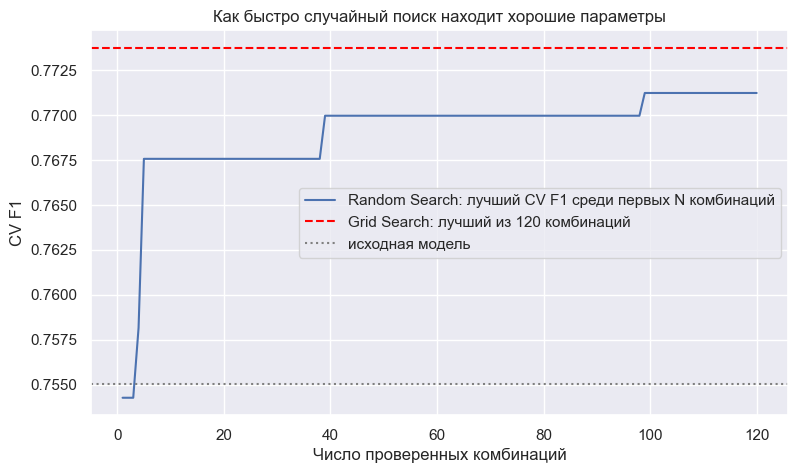

In [12]:
best_so_far = random_results["CV F1"].cummax()
close_enough = best_so_far >= grid_searcher.best_score_ - 0.005
if close_enough.any():
    print("Random Search впервые подошёл к лучшему результату сетки ближе чем на 0.005 после %d комбинаций" % (int(close_enough.idxmax()) + 1))
else:
    print("Random Search так и не подошёл к лучшему результату сетки ближе чем на 0.005")

plt.figure(figsize=(9, 5))
plt.plot(range(1, len(best_so_far) + 1), best_so_far, label="Random Search: лучший CV F1 среди первых N комбинаций")
plt.axhline(grid_searcher.best_score_, color="red", linestyle="--", label="Grid Search: лучший из %d комбинаций" % len(grid_results))
plt.axhline(baseline_cv["test_score"].mean(), color="gray", linestyle=":", label="исходная модель")
plt.xlabel("Число проверенных комбинаций")
plt.ylabel("CV F1")
plt.title("Как быстро случайный поиск находит хорошие параметры")
plt.legend()

Вывод:
- **По качеству**: лучший результат случайного поиска — CV F1 = 0.771 (`learning_rate` ≈ 0.21, 76 деревьев, `max_depth=3`), на 0.003 ниже, чем у сетки (0.774). Это гораздо меньше разброса по фолдам (≈0.03), т.е. по качеству поиски на равных.
- **По числу комбинаций**: одинаково, 120. Но случайный поиск проверил 120 разных значений `learning_rate` и 109 разных `n_estimators`, а сетка — только 4 и 5. Т.е. каждый параметр он исследовал гораздо подробнее.
- **По времени**: случайный поиск оказался даже чуть дольше (127 с против 93 с). Время определяется не только числом комбинаций, но и тем, какие они: в случайном поиске число деревьев в среднем больше (равномерно от 50 до 800, т.е. в среднем около 425, а в сетке среднее 310), а большие ансамбли обучаются дольше.
- На графике видно, что случайный поиск уже после 4–5 комбинаций лучше исходной модели, а после 39 подходит к лучшему результату сетки ближе чем на 0.005. Т.е. почти такое же качество можно было получить примерно за треть бюджета.

**Когда случайный поиск предпочтительнее полного перебора:**
1. **Много гиперпараметров.** Число комбинаций в сетке — произведение числа значений: 5 параметров по 5 значений — уже 3125 комбинаций. Случайный поиск работает с любым заданным бюджетом.
2. **Важны не все параметры.** Обычно качество сильно зависит от 1–2 параметров. Сетка тратит бюджет на повторение одних и тех же значений важного параметра (у нас всего 4 разных `learning_rate` на 120 комбинаций), а случайный поиск при том же бюджете пробует 120 разных значений каждого.
3. **Непрерывные параметры** (`learning_rate`, коэффициенты регуляризации): для сетки нужно заранее угадать, какие точки взять, а случайный поиск сам покрывает весь диапазон.
4. **Ограничено время**: случайный поиск можно остановить в любой момент и получить разумный результат, а неполная сетка покрывает пространство неравномерно.

Полный перебор имеет смысл, когда параметров мало, значений немного и хочется увидеть всю картину целиком (как на тепловой карте в следующей части).

# Часть 7. Влияние гиперпараметров

Для каждого из трёх параметров меняю его значение, а остальные два оставляю как у лучшей модели из Grid Search, и считаю F1 на train и на CV (`validation_curve`, те же 5 фолдов). Диапазоны беру шире, чем в сетке, чтобы увидеть края. Закрашенная полоса — ± одно стандартное отклонение CV по фолдам.

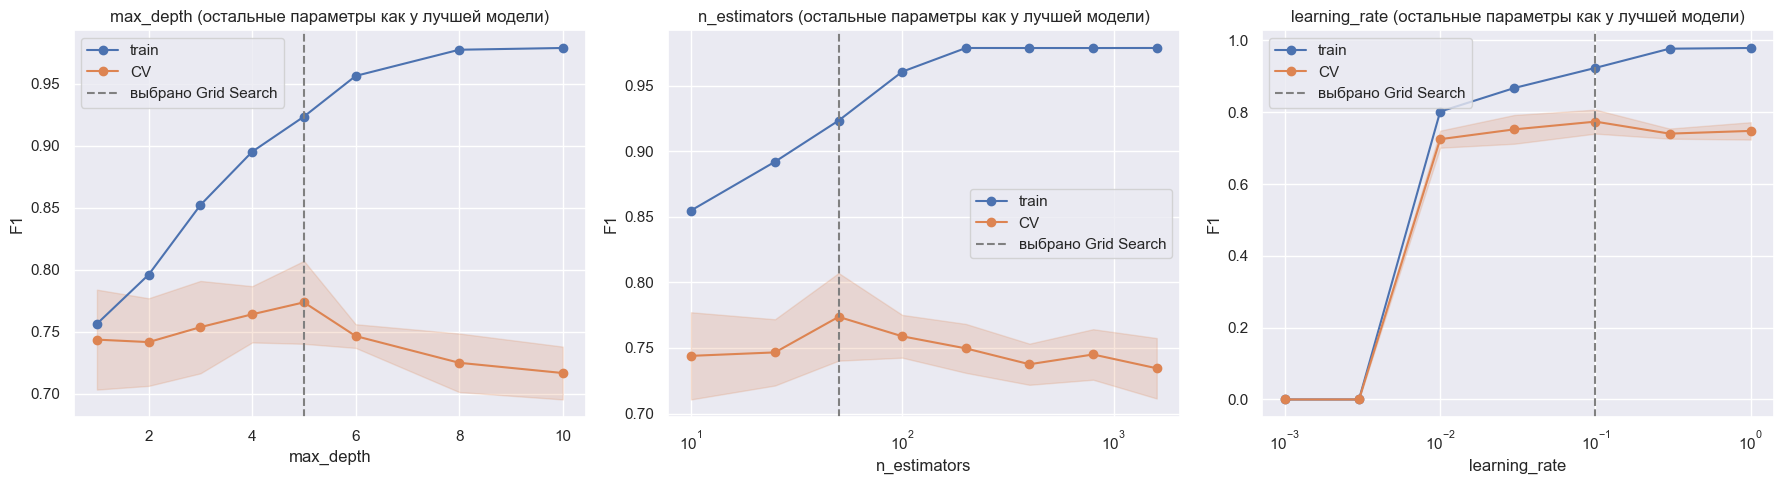

In [13]:
from sklearn.model_selection import validation_curve
from sklearn.base import clone

best_params = grid_searcher.best_params_

curves = {
    "model__max_depth": [1, 2, 3, 4, 5, 6, 8, 10],
    "model__n_estimators": [10, 25, 50, 100, 200, 400, 800, 1600],
    "model__learning_rate": [0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1.0],
}

curve_tables = {}
fig, axs = plt.subplots(figsize=(18, 5), ncols=3)
for ax, (param, values) in zip(axs, curves.items()):
    model = clone(baseline_model).set_params(**best_params)
    train_scores, cv_scores = validation_curve(model, X_train, y_train, param_name=param, param_range=values, cv=cv, scoring="f1", n_jobs=-1)
    name = param.replace("model__", "")
    curve_tables[name] = pd.DataFrame({"Train F1": train_scores.mean(axis=1), "CV F1": cv_scores.mean(axis=1), "CV std": cv_scores.std(axis=1)}, index=values)

    ax.plot(values, train_scores.mean(axis=1), "o-", label="train")
    ax.plot(values, cv_scores.mean(axis=1), "o-", label="CV")
    ax.fill_between(values, cv_scores.mean(axis=1) - cv_scores.std(axis=1), cv_scores.mean(axis=1) + cv_scores.std(axis=1), alpha=0.2, color="C1")
    ax.axvline(best_params[param], color="gray", linestyle="--", label="выбрано Grid Search")
    if name != "max_depth":
        ax.set_xscale("log")
    ax.set_xlabel(name)
    ax.set_ylabel("F1")
    ax.set_title("%s (остальные параметры как у лучшей модели)" % name)
    ax.legend()
plt.tight_layout()

In [14]:
for name, table in curve_tables.items():
    print(name)
    print(table.round(4), "\n")

max_depth
    Train F1   CV F1  CV std
1     0.7564  0.7437  0.0403
2     0.7961  0.7417  0.0353
3     0.8522  0.7538  0.0372
4     0.8951  0.7641  0.0227
5     0.9234  0.7738  0.0334
6     0.9562  0.7466  0.0095
8     0.9773  0.7250  0.0236
10    0.9787  0.7168  0.0213 

n_estimators
      Train F1   CV F1  CV std
10      0.8548  0.7440  0.0332
25      0.8921  0.7466  0.0253
50      0.9234  0.7738  0.0334
100     0.9607  0.7589  0.0163
200     0.9788  0.7497  0.0187
400     0.9788  0.7376  0.0157
800     0.9787  0.7451  0.0193
1600    0.9788  0.7345  0.0230 

learning_rate
       Train F1   CV F1  CV std
0.001    0.0000  0.0000  0.0000
0.003    0.0000  0.0000  0.0000
0.010    0.8017  0.7249  0.0238
0.030    0.8674  0.7522  0.0401
0.100    0.9234  0.7738  0.0334
0.300    0.9769  0.7403  0.0141
1.000    0.9789  0.7479  0.0242 



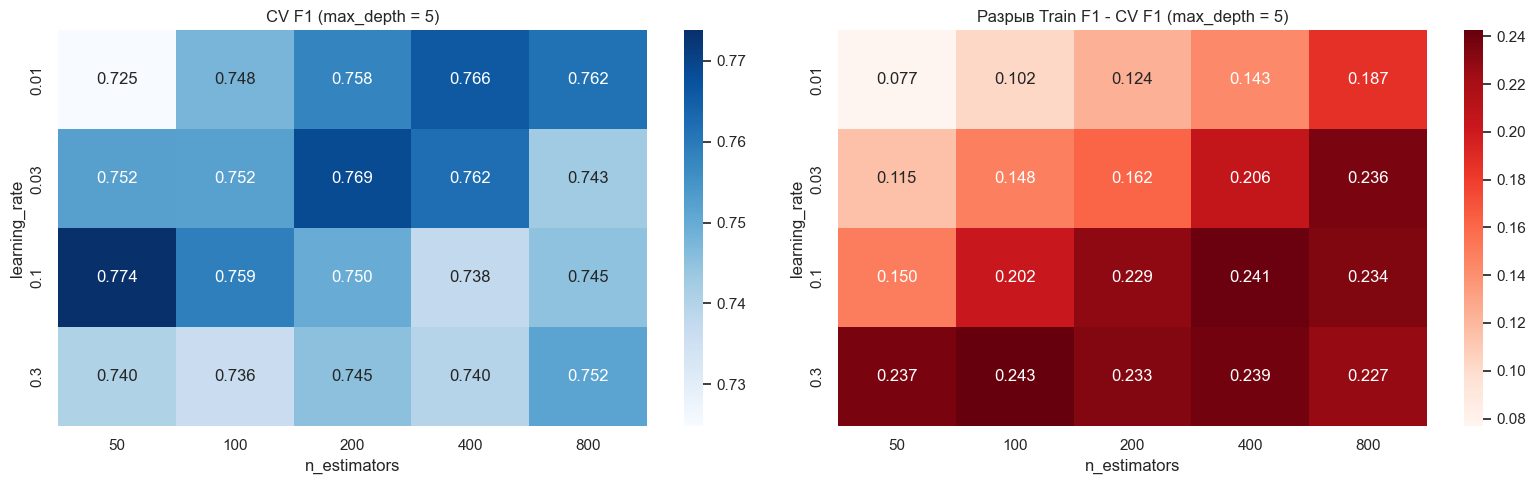

In [15]:
depth_slice = grid_results[grid_results["max_depth"] == best_params["model__max_depth"]]

fig, axs = plt.subplots(figsize=(16, 5), ncols=2)
sns.heatmap(depth_slice.pivot_table(index="learning_rate", columns="n_estimators", values="CV F1"), annot=True, fmt=".3f", cmap="Blues", ax=axs[0])
axs[0].set_title("CV F1 (max_depth = %d)" % best_params["model__max_depth"])
sns.heatmap(depth_slice.pivot_table(index="learning_rate", columns="n_estimators", values="Train F1") - depth_slice.pivot_table(index="learning_rate", columns="n_estimators", values="CV F1"),
            annot=True, fmt=".3f", cmap="Reds", ax=axs[1])
axs[1].set_title("Разрыв Train F1 - CV F1 (max_depth = %d)" % best_params["model__max_depth"])
plt.tight_layout()

Выводы.

**`max_depth`** (при `learning_rate=0.1`, 50 деревьев):
- **недообучение — глубина 1–2**: F1 и на train (0.76–0.80), и на CV (≈0.74) низкий и почти одинаковый. Пни (глубина 1) описывают только эффекты отдельных признаков, а взаимодействие «пол × класс», которое мы видели во второй лабораторной, им недоступно;
- **разумная сложность — глубина 3–5**: CV растёт до максимума 0.774 при глубине 5;
- **переобучение — глубина 6 и больше**: train F1 растёт до 0.98, а CV падает до 0.72 при глубине 10. Глубокие деревья на 712 пассажирах выучивают отдельных пассажиров вместе с шумом.

**`n_estimators`** (при `learning_rate=0.1`, глубина 5):
- **недообучение — 10–25 деревьев**: CV ≈ 0.745, бустинг сделал слишком мало шагов;
- **разумная сложность — около 50 деревьев** (CV 0.774);
- **переобучение — 100 деревьев и больше**: train F1 быстро доходит до 0.98 и дальше не растёт (модель уже выучила train почти полностью), а CV постепенно снижается до 0.735. Каждое следующее дерево исправляет «ошибки» на train, которые на самом деле являются шумом.

**`learning_rate`** (при 50 деревьях глубины 5):
- **сильное недообучение — 0.001 и 0.003**: F1 = 0 и на train, и на CV. За 50 маленьких шагов модель почти не сдвигается от начального предсказания (доля выживших 38%), все вероятности остаются ниже 0.5, и модель всем говорит «погиб» — как baseline из второй лабораторной;
- **0.01–0.03** — модель ещё недоучена (CV 0.725–0.752);
- **разумно — 0.1** (CV 0.774);
- **переобучение — 0.3 и больше**: train F1 0.98, CV падает до 0.74–0.75.

**Тепловая карта `learning_rate` × `n_estimators`** (при глубине 5) показывает главное про эти два параметра: хорошие значения лежат на «диагонали» — 0.01 × 400, 0.03 × 200, 0.1 × 50. Т.е. важно не каждое значение отдельно, а их сочетание: маленький шаг требует много деревьев, большой — мало. Правее и ниже диагонали (много деревьев и большой шаг) — переобучение: на правой карте разрыв train − CV там 0.23–0.24. В левом верхнем углу (мало деревьев, маленький шаг) разрыв всего 0.08, но там модель недоучена и CV ниже.

**Оговорка про шум.** Разброс CV по фолдам ≈ 0.01–0.04, и разница между соседними точками кривых часто меньше. Поэтому точное положение максимума (глубина 5, а не 4; 50 деревьев, а не 100) определено неуверенно, а вот общая форма кривых — рост, максимум и спад — видна хорошо.

# Часть 8. Финальная модель

Подбор закончен. Теперь обучаю три модели на всём train (у `GridSearchCV` и `RandomizedSearchCV` это уже сделано автоматически: `refit=True`, лучшие параметры переобучаются на всём train) и **только после этого** один раз оцениваю их на тесте.

In [16]:
from sklearn.metrics import f1_score, accuracy_score

def best_fold_scores(searcher):
    return np.array([searcher.cv_results_["split%d_test_score" % i][searcher.best_index_] for i in range(cv.get_n_splits())])

final_models = {
    "Исходная модель": clone(baseline_model).fit(X_train, y_train),
    "Grid Search": grid_searcher.best_estimator_,
    "Random Search": random_searcher.best_estimator_,
}
fold_scores = {
    "Исходная модель": baseline_cv["test_score"],
    "Grid Search": best_fold_scores(grid_searcher),
    "Random Search": best_fold_scores(random_searcher),
}

final_table = {}
for name, model in final_models.items():
    model_params = model.named_steps["model"].get_params()
    y_pred = model.predict(X_test)
    final_table[name] = {
        "learning_rate": model_params["learning_rate"],
        "n_estimators": model_params["n_estimators"],
        "max_depth": model_params["max_depth"],
        "CV F1": fold_scores[name].mean(),
        "CV std": fold_scores[name].std(),
        "Train F1": f1_score(y_train, model.predict(X_train)),
        "Test F1": f1_score(y_test, y_pred),
        "Test Accuracy": accuracy_score(y_test, y_pred),
    }
final_table = pd.DataFrame(final_table).T
final_table.round(4)

,learning_rate,n_estimators,max_depth,CV F1,CV std,Train F1,Test F1,Test Accuracy
Исходная модель,0.1000,100.0,3.0,0.7550,0.0257,0.8851,0.7402,0.8156
Grid Search,0.1000,50.0,5.0,0.7738,0.0334,0.9198,0.7692,0.8324
Random Search,0.2078,76.0,3.0,0.7712,0.0329,0.9091,0.7656,0.8324


Выводы:
- **Насколько оптимизация улучшила качество.** По кросс-валидации: исходная модель 0.755, Grid Search 0.774 (+0.019), Random Search 0.771 (+0.016). На тесте: 0.740 → 0.769 (+0.029) и 0.766 (+0.026), Accuracy 0.816 → 0.832. Т.е. и на CV, и на тесте подобранные модели лучше исходной на 0.02–0.03 по F1.
- **Совпадает ли улучшение на CV с тестом.** По направлению да: обе подобранные модели лучше исходной и на CV, и на тесте, порядок моделей тот же (Grid Search ≥ Random Search > исходная). По величине тест показывает даже больший выигрыш, чем CV.
- **Но доверять этой разнице нужно осторожно.** На тесте всего 69 выживших, и разница в 0.03 по F1 — это несколько правильно найденных выживших. Разброс CV по фолдам (0.026–0.033) того же порядка, что и само улучшение. А лучший CV score — это максимум из 120 комбинаций, оценённых на одних и тех же 5 фолдах, и такой максимум систематически завышен: часть «улучшения» может быть просто удачным совпадением конкретной комбинации с конкретными фолдами. Насколько это так, проверю в части 9 на новых разбиениях.

Ещё деталь: у подобранных моделей F1 на train выше (0.92 и 0.91 против 0.89), т.е. они сложнее исходной и сильнее подстраиваются под train.

# Часть 9. Анализ устойчивости

Смотрю не только на среднее по фолдам, но и на каждый фолд отдельно.

        Исходная модель  Grid Search  Random Search
фолд 1           0.7778       0.7810         0.7885
фолд 2           0.7184       0.7850         0.7358
фолд 3           0.7879       0.8269         0.8269
фолд 4           0.7358       0.7358         0.7477
фолд 5           0.7551       0.7400         0.7573

std: {'Исходная модель': 0.0257, 'Grid Search': 0.0334, 'Random Search': 0.0329}
max - min: {'Исходная модель': 0.0694, 'Grid Search': 0.0911, 'Random Search': 0.0911}


Text(0.5, 1.0, 'F1 по фолдам кросс-валидации')

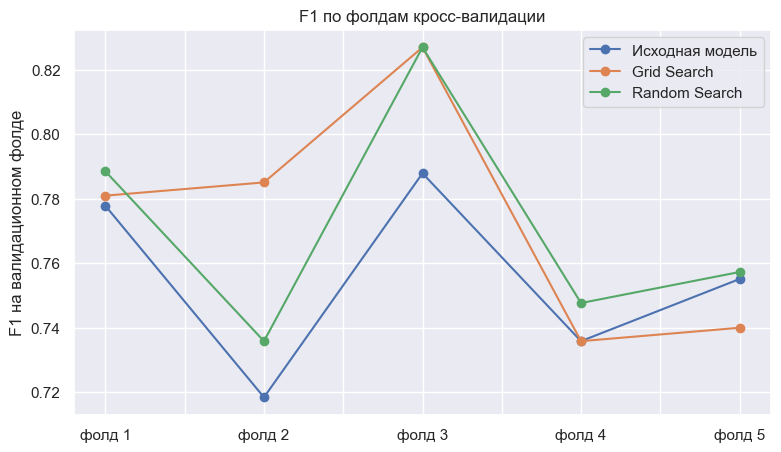

In [17]:
folds_table = pd.DataFrame(fold_scores, index=["фолд %d" % (i + 1) for i in range(cv.get_n_splits())])
print(folds_table.round(4))
print("\nstd:", folds_table.std(ddof=0).round(4).to_dict())
print("max - min:", (folds_table.max() - folds_table.min()).round(4).to_dict())

folds_table.plot(marker="o", figsize=(9, 5))
plt.ylabel("F1 на валидационном фолде")
plt.title("F1 по фолдам кросс-валидации")

Выводы:
- Разброс по фолдам большой у всех трёх моделей: std 0.026–0.033, а разница между лучшим и худшим фолдом 0.07–0.09. Это больше, чем то, насколько подбор «улучшил» среднее (≈0.02).
- «Сложные» и «лёгкие» фолды у всех моделей одни и те же: на 4-м фолде все три получают около 0.74–0.75, на 3-м — 0.79–0.83. Т.е. разброс в основном определяется не моделью, а тем, какие пассажиры попали в фолд: на ~142 пассажирах достаточно нескольких «нетипичных» выживших, чтобы F1 изменился на 0.03.
- Выигрыш подобранных моделей неравномерный: Grid Search сильно лучше исходной модели на 2-м и 3-м фолдах (+0.07 и +0.04), одинаков на 4-м и даже хуже на 5-м (0.740 против 0.755). Т.е. среднее «+0.019» складывается из большого выигрыша на паре фолдов, а не из стабильного улучшения на всех.

Найду в результатах Grid Search две комбинации с почти одинаковым средним CV F1 (разница меньше 0.003), но с максимально разным разбросом по фолдам.

In [18]:
top = grid_results.sort_values("CV F1", ascending=False).head(30).reset_index(drop=True)

best_pair, best_diff = None, 0
for i in range(len(top)):
    for j in range(i + 1, len(top)):
        if abs(top.loc[i, "CV F1"] - top.loc[j, "CV F1"]) < 0.003 and abs(top.loc[i, "CV std"] - top.loc[j, "CV std"]) > best_diff:
            best_pair, best_diff = (i, j), abs(top.loc[i, "CV std"] - top.loc[j, "CV std"])

split_columns = ["split%d_test_score" % i for i in range(cv.get_n_splits())]
pair = top.loc[list(best_pair), ["learning_rate", "n_estimators", "max_depth", "CV F1", "CV std"] + split_columns]
pair.round(4)

,learning_rate,n_estimators,max_depth,CV F1,CV std,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score
14,0.10,400,3,0.7612,0.0088,0.7778,0.7523,0.7619,0.7568,0.7573
17,0.01,800,1,0.7611,0.0483,0.7500,0.7255,0.8491,0.7115,0.7692


Вот пример двух моделей с практически одинаковым средним CV F1 (0.761), но совсем разной устойчивостью:
- `learning_rate=0.1`, 400 деревьев глубины 3 — F1 на всех фолдах от 0.752 до 0.778, std = 0.009;
- `learning_rate=0.01`, 800 деревьев глубины 1 — F1 от 0.712 до 0.849, std = 0.048.

**Почему так бывает.** Среднее не говорит о том, как именно модель ошибается. Модели разной структуры по-разному реагируют на состав фолда. Модель из «пней» (глубина 1) описывает только эффекты отдельных признаков и для похожих пассажиров даёт почти одинаковый ответ, поэтому её F1, скорее всего, сильно зависит от того, сколько «нетипичных» пассажиров (например, выживших мужчин или погибших женщин третьего класса) попало в фолд: на одних фолдах ей везёт, на других нет. При одинаковом среднем устойчивая модель предпочтительнее: на новых данных её качество предсказуемее, а у неустойчивой оно может оказаться и сильно лучше, и сильно хуже среднего.

Похожий пример есть и среди лучших комбинаций (часть 5): `learning_rate=0.1` с 50 деревьями глубины 5 (CV 0.774, std 0.033) и `learning_rate=0.01` с 800 деревьями глубины 4 (CV 0.773, std 0.013). По среднему они равны, но вторая в 2.5 раза устойчивее, и при честном выборе её можно было бы предпочесть.

Ещё одна проверка устойчивости: лучшие параметры выбраны как максимум среднего F1 на **конкретных** 5 фолдах. Проверю выбранные модели на других разбиениях — повторю 5-фолдовую кросс-валидацию 5 раз с другим `random_state` (25 оценок на модель). Тест здесь по-прежнему не используется.

In [19]:
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score

repeated_cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=1)

repeat_check = {}
repeat_scores = {}
for name, model in final_models.items():
    scores = cross_val_score(clone(model), X_train, y_train, cv=repeated_cv, scoring="f1", n_jobs=-1)
    repeat_scores[name] = scores
    repeat_check[name] = {
        "CV F1 (5 фолдов поиска)": fold_scores[name].mean(),
        "CV F1 (5x5 новых фолдов)": scores.mean(),
        "std (5x5)": scores.std(),
        "min": scores.min(),
        "max": scores.max(),
    }
pd.DataFrame(repeat_check).T.round(4)

,CV F1 (5 фолдов поиска),CV F1 (5x5 новых фолдов),std (5x5),min,max
Исходная модель,0.7550,0.7619,0.0332,0.7083,0.8269
Grid Search,0.7738,0.7618,0.0357,0.7083,0.8367
Random Search,0.7712,0.7612,0.0353,0.7021,0.8364


Text(0.5, 1.0, 'Повторная кросс-валидация 5x5 (25 оценок на модель)')

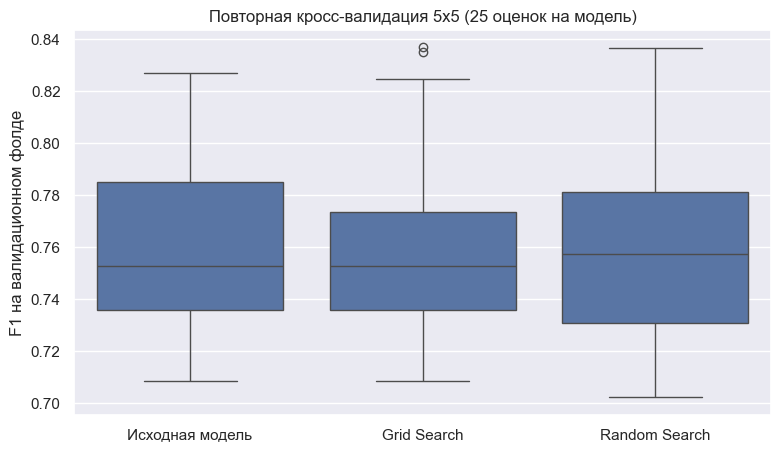

In [20]:
plt.figure(figsize=(9, 5))
sns.boxplot(data=pd.DataFrame(repeat_scores), color="C0")
plt.ylabel("F1 на валидационном фолде")
plt.title("Повторная кросс-валидация 5x5 (25 оценок на модель)")

Это, пожалуй, самый важный результат лабораторной:
- На **новых** разбиениях (25 оценок на модель) все три модели дают **одинаковый** средний F1: 0.762 у исходной модели, 0.762 у Grid Search и 0.761 у Random Search, с почти одинаковым разбросом (std 0.033–0.036). Разница между ними в тысячных, а разброс по фолдам в десятки раз больше.
- Т.е. «улучшение» +0.02 на 5 фолдах поиска почти целиком оказалось **оптимизмом выбора**: лучшая комбинация — это максимум из 120 шумных оценок на одних и тех же фолдах, и она лучшая отчасти потому, что ей повезло именно с этими фолдами. На других разбиениях преимущество исчезает: CV F1 подобранных моделей упал с 0.774 и 0.771 до 0.762, а у исходной модели, которую никто не выбирал, наоборот, вырос с 0.755 до 0.762 — её 5 фолдов поиска оказались для неё неудачными.
- Значит, и выигрыш на тесте (+0.03) не стоит считать доказательством того, что подобранные модели лучше: на 179 пассажирах это может быть такое же удачное совпадение.

Вывод: на таком маленьком датасете параметры бустинга по умолчанию уже близки к оптимальным, и подбор гиперпараметров не даёт улучшения, которое можно надёжно отличить от шума. Это не значит, что подбор бесполезен: он показал, где модель недообучается и где переобучается (часть 7), и подтвердил, что исходные параметры лежат в разумной области. А чтобы честно оценить выигрыш от подбора, выбранную модель нужно проверять на данных, которые не участвовали в выборе: на повторной кросс-валидации с другими разбиениями (как здесь) или с помощью вложенной кросс-валидации (nested CV), где подбор параметров повторяется внутри каждого внешнего фолда.

# Часть 10. Честный эксперимент

Что сделано, чтобы эксперимент был честным:
- Разбиение train/test сделано один раз в самом начале с фиксированным `random_state`, и тестовая выборка ни разу не использовалась для выбора чего-либо.
- Число фолдов, все гиперпараметры (Grid Search, Random Search) и анализ влияния параметров считались только на train через кросс-валидацию.
- Препроцессинг (заполнение пропусков, one-hot) стоит внутри `Pipeline`, поэтому при кросс-валидации он обучается только на обучающих фолдах, и информация из валидационного фолда в обучение не протекает.
- На тесте все три модели оценены один раз, в части 8, уже после того, как параметры были выбраны. После этого ничего не менялось.
- Проверка устойчивости (часть 9) тоже делалась только на train: повторная кросс-валидация на новых разбиениях train, без теста.

# Итоги

| Модель | `learning_rate` | `n_estimators` | `max_depth` | CV F1 (фолды поиска) | CV F1 (5x5 новых фолдов) | Test F1 |
|---|---|---|---|---|---|---|
| Исходная модель | 0.1 | 100 | 3 | 0.755 ± 0.026 | 0.762 | 0.740 |
| Grid Search | 0.1 | 50 | 5 | 0.774 ± 0.033 | 0.762 | 0.769 |
| Random Search | 0.21 | 76 | 3 | 0.771 ± 0.033 | 0.761 | 0.766 |

- Задача — Titanic из второй лабораторной (метрика F1), модель — Gradient Boosting. Подбирались три гиперпараметра: `n_estimators`, `learning_rate` и `max_depth`. Для подбора использовалась стратифицированная 5-фолдовая кросс-валидация на train, тест использован один раз в конце.
- Grid Search: 120 комбинаций, около 93 с, лучший CV F1 = 0.774. Random Search с тем же бюджетом: 0.771, около 127 с, но он проверил гораздо больше разных значений каждого параметра и подошёл к результату сетки уже после 39 комбинаций.
- По кривым видно: недообучение — неглубокие деревья (1–2), мало деревьев или очень маленький `learning_rate`; разумная сложность — глубина 3–5 и «диагональ» `learning_rate` × `n_estimators`; переобучение — глубина от 6, много деревьев при большом шаге, `learning_rate` от 0.3.
- На тесте подобранные модели лучше исходной на ~0.03 F1, но повторная кросс-валидация на новых разбиениях показывает, что все три модели одинаковые (≈0.762). Выигрыш на фолдах поиска — во многом оптимизм выбора лучшей из 120 шумных оценок, а на таком маленьком датасете параметры по умолчанию уже близки к оптимальным.
- Разброс по фолдам (0.07–0.09 между лучшим и худшим фолдом) больше, чем выигрыш от подбора, а модели с одинаковым средним могут сильно различаться по устойчивости — поэтому смотреть нужно не только на среднее.